In [ ]:
!pip install sentinelhub rasterio geopandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.8/249.8 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.2 MB 53.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 236.0/236.0 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 3.3 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import rasterio
from datetime import datetime, timedelta
from sentinelhub import (
    SHConfig, BBox, CRS, SentinelHubRequest, MimeType,
    DataCollection, bbox_to_dimensions, MosaickingOrder
)
from rasterio.transform import from_bounds
from google.colab import files

# === Sentinel Hub Config ===
config = SHConfig()
config.sh_client_id = ""
config.sh_client_secret = ""
config.download_timeout_seconds = 60

# === Region definitions ===
regions = {
    "Thar": [70.905, 26.906, 70.925, 26.924],
}

# === Date range for 4 years ===
start_date = datetime(2021, 6, 1)
end_date = datetime(2023, 6, 1)
date_list = [start_date + timedelta(days=i) for i in range((end_date - start_date).days + 1)]

# === Evalscript (7 bands) ===
evalscript = """
//VERSION=3
function setup() {
  return {
    input: ["B02", "B03", "B04", "B05", "B08", "B11", "B12"],
    output: { bands: 7, sampleType: "FLOAT32" }
  };
}
function evaluatePixel(sample) {
  return [
    sample.B02, sample.B03, sample.B04,
    sample.B05, sample.B08, sample.B11, sample.B12
  ];
}
"""

# === Data collection ===
all_data = []

for region_name, coords in regions.items():
    bbox = BBox(bbox=coords, crs=CRS.WGS84)
    size = bbox_to_dimensions(bbox, resolution=10)

    for date in date_list:
        date_str = date.strftime('%Y-%m-%d')
        print(f"\n📦 Fetching for {region_name} - {date_str}")
        try:
            request = SentinelHubRequest(
                evalscript=evalscript,
                input_data=[SentinelHubRequest.input_data(
                    data_collection=DataCollection.SENTINEL2_L2A,
                    time_interval=(date_str, date_str),
                    mosaicking_order=MosaickingOrder.MOST_RECENT
                )],
                responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
                bbox=bbox,
                size=size,
                config=config
            )

            images = request.get_data(save_data=False)
            if not images:
                print("⚠ No image returned.")
                continue

            image = images[0]
            blue, green, red, red_edge, nir, swir1, swir2 = image[:7]

            if np.all(nir == 0) or np.all(red == 0):
                print("⚠ Image is empty (all zeros). Skipping.")
                continue

            # Compute indices
            ndvi = (nir - red) / (nir + red + 1e-6)
            savi = (nir - red) * 1.5 / (nir + red + 0.5)
            ndmi = (nir - swir1) / (nir + swir1 + 1e-6)
            evi = 2.5 * (nir - red) / (nir + 6 * red - 7.5 * blue + 1)
            revi = (red_edge - red) / (red_edge + red + 1e-6)
            gndvi = (nir - green) / (nir + green + 1e-6)
            msavi = (2 * nir + 1 - np.sqrt((2 * nir + 1) ** 2 - 8 * (nir - red))) / 2
            ndwi = (green - nir) / (green + nir + 1e-6)
            lswi = (nir - swir1) / (nir + swir1 + 1e-6)

            transform = from_bounds(*bbox, width=ndvi.shape[1], height=ndvi.shape[0])
            for y in range(ndvi.shape[0]):
                for x in range(ndvi.shape[1]):
                    if np.isnan(ndvi[y, x]):
                        continue
                    lat, lon = rasterio.transform.xy(transform, y, x)
                    all_data.append({
                        "timestamp": date_str,
                        "region": region_name,
                        "latitude": lat,
                        "longitude": lon,
                        "ndvi": float(ndvi[y, x]),
                        "savi": float(savi[y, x]),
                        "ndmi": float(ndmi[y, x]),
                        "evi": float(evi[y, x]),
                        "revi": float(revi[y, x]),
                        "gndvi": float(revi[y, x]),
                        "msavi": float(revi[y, x]),
                        "ndwi": float(revi[y, x]),
                        "lswi": float(revi[y, x])
                    })

            print(f"✅ Done for {region_name} - {date_str}")

        except Exception as e:
            print(f"❌ Error for {region_name} - {date_str}: {e}")
            continue

# === Export to CSV ===
df = pd.DataFrame(all_data)
df.to_csv("Naive_Bayes_Thar_Model.csv", index=False)
files.download("Naive_Bayes_Thar_Model.csv")



📦 Fetching for Thar - 2021-06-01
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-02
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-03
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-04
✅ Done for Thar - 2021-06-04

📦 Fetching for Thar - 2021-06-05
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-06
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-07
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-08
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-09
✅ Done for Thar - 2021-06-09

📦 Fetching for Thar - 2021-06-10
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-11
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-12
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-13
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-14
✅ Done for Thar - 2021-06-

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# DATA PRE-PROCESSING

import pandas as pd
from google.colab import files

# Load the previously extracted file
df = pd.read_csv("Naive_Bayes_Thar_Model.csv")

# Drop rows with missing values
df = df.dropna()

# Convert columns to correct types
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
for col in ['latitude', 'longitude', 'ndvi', 'savi', 'ndmi', 'evi', 'revi', 'gndvi', 'msavi', 'ndwi', 'lswi']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Filter out invalid NDVI values (e.g., zero or negative)
df = df[df['ndvi'] <= 1] # the range of ndvi > 0 is not ommitted to let the model check if ndvi == (-1) shows no crop growth

# Remove duplicates
df = df.drop_duplicates()

# Save cleaned file
df.to_csv("Naive_Bayes_Thar_Model_CLEANED.csv", index=False)
files.download("Naive_Bayes_Thar_Model_CLEANED.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STANDARDIZATION (Z-SCORE)

from sklearn.preprocessing import StandardScaler
import pandas as pd
from google.colab import files

# Load the CSV file
df = pd.read_csv('Naive_Bayes_Thar_Model_CLEANED.csv')

# Select vegetation index columns for scaling
vi_columns = ['ndvi', 'savi', 'ndmi', 'evi', 'revi', 'gndvi', 'msavi', 'ndwi', 'lswi']

# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the VI columns
df_scaled = df.copy()
df_scaled[vi_columns] = scaler.fit_transform(df[vi_columns])

# Clip all values to range [-1, 1]
df_scaled[vi_columns] = df_scaled[vi_columns].clip(lower=-1, upper=1)

# Save the standardized and clipped data to a new CSV
df_scaled.to_csv('Naive_Bayes_Thar_Model_STANDARDIZED.csv', index=False)
files.download("Naive_Bayes_Thar_Model_STANDARDIZED.csv")

print("✅ Z-score standardization + clipping complete. File saved.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Z-score standardization + clipping complete. File saved.


In [ ]:
df = pd.read_csv("Naive_Bayes_Thar_Model_STANDARDIZED.csv")
print(df[['ndvi', 'savi', 'ndmi', 'evi', 'revi']].describe())
# to check if mean is approximately 0 == standardized data

                ndvi           savi           ndmi            evi  \
count  200312.000000  200312.000000  200312.000000  200312.000000   
mean       -0.008422      -0.002334       0.009329       0.000173   
std         0.571577       0.610729       0.557065       0.065905   
min        -1.000000      -1.000000      -1.000000      -1.000000   
25%        -0.349035      -0.415758      -0.274154      -0.014266   
50%        -0.023375      -0.016091       0.047984       0.000748   
75%         0.332556       0.415290       0.279652       0.015456   
max         1.000000       1.000000       1.000000       1.000000   

                revi  
count  200312.000000  
mean        0.008796  
std         0.548879  
min        -1.000000  
25%        -0.254169  
50%         0.045737  
75%         0.255032  
max         1.000000  


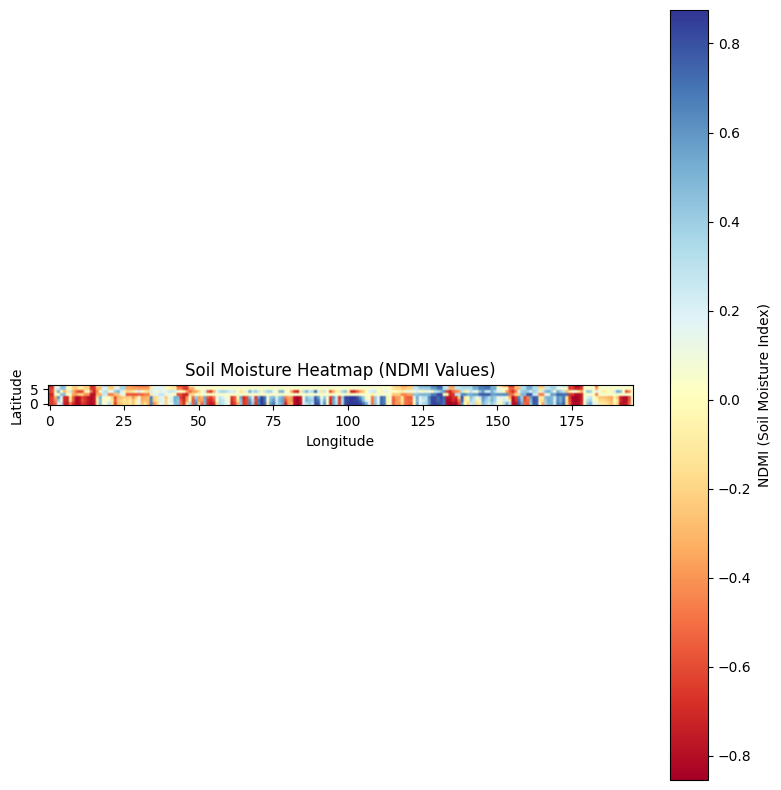

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Load your NDMI data ===
df = pd.read_csv("Naive_Bayes_Thar_Model_STANDARDIZED.csv")

# === Drop missing NDMI and round coordinates ===
df = df.dropna(subset=['ndmi'])
df['Latitude'] = df['latitude'].round(5)
df['Longitude'] = df['longitude'].round(5)

# === Pivot the data to form a grid ===
grid = df.pivot_table(index='Latitude', columns='Longitude', values='ndmi')

# === Plot heatmap ===
plt.figure(figsize=(8, 8))
im = plt.imshow(grid, cmap='RdYlBu', origin='lower', aspect='equal')
cbar = plt.colorbar(im)
cbar.set_label("NDMI (Soil Moisture Index)")

plt.title("Soil Moisture Heatmap (NDMI Values)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

In [ ]:
# Aggregated (non-pixelated) data

import pandas as pd
from google.colab import files

# Load the cleaned file with pixel-wise data
df = pd.read_csv("Naive_Bayes_Thar_Model_CLEANED.csv")

# Ensure timestamp is in datetime format
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df = df.dropna(subset=['timestamp', 'region'])  # Ensure no missing region

# Create a 'date' column for daily aggregation
df['date'] = df['timestamp'].dt.date

# Group by both date and region
daily_avg = df.groupby(['date', 'region']).agg({
    'ndvi': 'mean',
    'savi': 'mean',
    'ndmi': 'mean',
    'evi': 'mean',
    'revi': 'mean',
    'gndvi': 'mean',
    'msavi': 'mean',
    'ndwi': 'mean',
    'lswi': 'mean'
}).reset_index()

# Save the aggregated data
daily_avg.to_csv("Naive_Bayes_Thar_Model_Aggregated_Daily_VI.csv", index=False)
files.download("Naive_Bayes_Thar_Model_Aggregated_Daily_VI.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(df['timestamp'].dt.date.nunique())
print(sorted(df['timestamp'].dt.date.unique()))

146
[datetime.date(2021, 6, 4), datetime.date(2021, 6, 9), datetime.date(2021, 6, 14), datetime.date(2021, 6, 19), datetime.date(2021, 6, 24), datetime.date(2021, 6, 29), datetime.date(2021, 7, 4), datetime.date(2021, 7, 9), datetime.date(2021, 7, 14), datetime.date(2021, 7, 19), datetime.date(2021, 7, 24), datetime.date(2021, 7, 29), datetime.date(2021, 8, 3), datetime.date(2021, 8, 8), datetime.date(2021, 8, 13), datetime.date(2021, 8, 18), datetime.date(2021, 8, 23), datetime.date(2021, 8, 28), datetime.date(2021, 9, 2), datetime.date(2021, 9, 7), datetime.date(2021, 9, 12), datetime.date(2021, 9, 17), datetime.date(2021, 9, 22), datetime.date(2021, 9, 27), datetime.date(2021, 10, 2), datetime.date(2021, 10, 7), datetime.date(2021, 10, 12), datetime.date(2021, 10, 17), datetime.date(2021, 10, 22), datetime.date(2021, 10, 27), datetime.date(2021, 11, 1), datetime.date(2021, 11, 6), datetime.date(2021, 11, 11), datetime.date(2021, 11, 16), datetime.date(2021, 11, 21), datetime.date(20

In [ ]:
# STANDARDIZATION (Z-SCORE)

from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
from google.colab import files

# Load the aggregated file
df = pd.read_csv('Naive_Bayes_Thar_Model_Aggregated_Daily_VI.csv')

# List of VI columns
vi_columns = ['ndvi', 'savi', 'ndmi', 'evi', 'revi', 'gndvi', 'msavi', 'ndwi', 'lswi']

# === Sanity checks ===
# Replace inf/-inf with NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Drop rows with NaNs in VI columns
df.dropna(subset=vi_columns, inplace=True)

# Optionally filter out extreme values (rare spikes)
for col in vi_columns:
    df = df[(df[col] > -5) & (df[col] < 5)]

# === Standardization ===
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[vi_columns] = scaler.fit_transform(df[vi_columns])

# Clip values between -1 and 1 (optional, for consistency)
df_scaled[vi_columns] = df_scaled[vi_columns].clip(lower=-1, upper=1)

# === Export the result ===
df_scaled.to_csv('Naive_Bayes_Thar_Model_Aggregated_Daily_VI_STANDARDIZED.csv', index=False)
files.download("Naive_Bayes_Thar_Model_Aggregated_Daily_VI_STANDARDIZED.csv")

print("✅ Standardization (Z-score) and clipping complete.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Standardization (Z-score) and clipping complete.


In [ ]:
df = pd.read_csv("Naive_Bayes_Thar_Model_Aggregated_Daily_VI_STANDARDIZED.csv")
print(df[['ndvi', 'savi', 'ndmi', 'evi', 'revi', 'gndvi', 'msavi', 'ndwi', 'lswi']].describe())
# to check if mean is approximately 0 == standardized data

             ndvi        savi        ndmi         evi        revi       gndvi  \
count  146.000000  146.000000  146.000000  146.000000  146.000000  146.000000   
mean    -0.039165   -0.025485    0.012944   -0.009845    0.004658    0.004658   
std      0.669440    0.660129    0.669446    0.352905    0.642787    0.642787   
min     -1.000000   -1.000000   -1.000000   -1.000000   -1.000000   -1.000000   
25%     -0.606916   -0.590502   -0.594615   -0.049547   -0.486876   -0.486876   
50%     -0.062396   -0.074925    0.005894    0.023018    0.188739    0.188739   
75%      0.574456    0.552228    0.613473    0.111926    0.493630    0.493630   
max      1.000000    1.000000    1.000000    1.000000    1.000000    1.000000   

            msavi        ndwi        lswi  
count  146.000000  146.000000  146.000000  
mean     0.004658    0.004658    0.004658  
std      0.642787    0.642787    0.642787  
min     -1.000000   -1.000000   -1.000000  
25%     -0.486876   -0.486876   -0.486876  
50%   

📋 Validation Report:
              precision    recall  f1-score   support

           0       0.83      0.91      0.87        11
           1       0.60      0.60      0.60         5
           2       1.00      0.92      0.96        13

    accuracy                           0.86        29
   macro avg       0.81      0.81      0.81        29
weighted avg       0.87      0.86      0.86        29


🧪 Test Report:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95        11
           1       0.86      1.00      0.92         6
           2       1.00      1.00      1.00        13

    accuracy                           0.97        30
   macro avg       0.95      0.97      0.96        30
weighted avg       0.97      0.97      0.97        30


🎯 Final Accuracy on Test Set: 0.9667


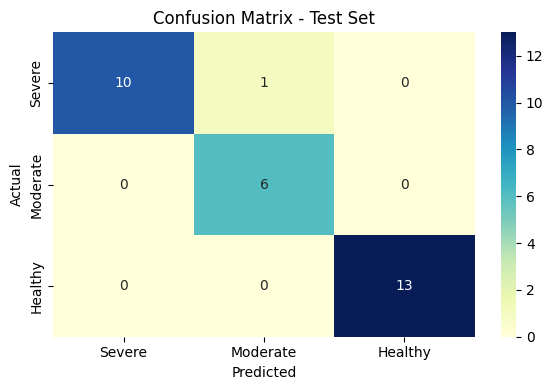

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ CSV saved: Naive_Bayes_Thar_Model_PREDICTED.csv


In [ ]:
# NAIVE BAYES WITH NDMI THRESHOLD

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# === 1. Load Data ===
df = pd.read_csv("Naive_Bayes_Thar_Model_Aggregated_Daily_VI_STANDARDIZED.csv")

# === 2. Label NDMI thresholds for soil moisture ===
# 0: Severe | 1: Moderate | 2: Healthy
def label_soil_moisture(ndmi):
    if ndmi < -0.2:
        return 0  # Severe
    elif ndmi <= 0.1:
        return 1  # Moderate
    else:
        return 2  # Healthy

df['label'] = df['ndmi'].apply(label_soil_moisture)

# === 3. Feature and Target ===
#X = df[['ndmi']]
X = df[['ndvi', 'savi', 'ndmi', 'evi', 'revi', 'gndvi', 'msavi', 'ndwi', 'lswi']]
#X = df[['ndvi', 'savi', 'evi', 'revi', 'gndvi', 'msavi', 'ndwi', 'lswi']]
y = df['label']

# === 4. Train-Test Split ===
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# === 5. Train Naive Bayes Model ===
model = GaussianNB()
model.fit(X_train, y_train)

# === 6. Predict & Evaluate ===
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

# Validation Report
print("📋 Validation Report:")
print(classification_report(y_val, y_val_pred))

# Test Report
print("\n🧪 Test Report:")
print(classification_report(y_test, y_test_pred))

# Final accuracy
acc = accuracy_score(y_test, y_test_pred)
print(f"\n🎯 Final Accuracy on Test Set: {acc:.4f}")

# === 7. Confusion Matrix ===
labels = ['Severe', 'Moderate', 'Healthy']
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1, 2])
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix - Test Set")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# === 8. Predict for full dataset and save ===
df['Predicted_Label'] = model.predict(X)
label_map = {0: 'Severe', 1: 'Moderate', 2: 'Healthy'}
df['Predicted_Soil_Moisture'] = df['Predicted_Label'].map(label_map)

# === 9. Save to new CSV ===
df.to_csv("Naive_Bayes_Thar_Model_PREDICTED.csv", index=False)
files.download("Naive_Bayes_Thar_Model_PREDICTED.csv")
print("✅ CSV saved: Naive_Bayes_Thar_Model_PREDICTED.csv")

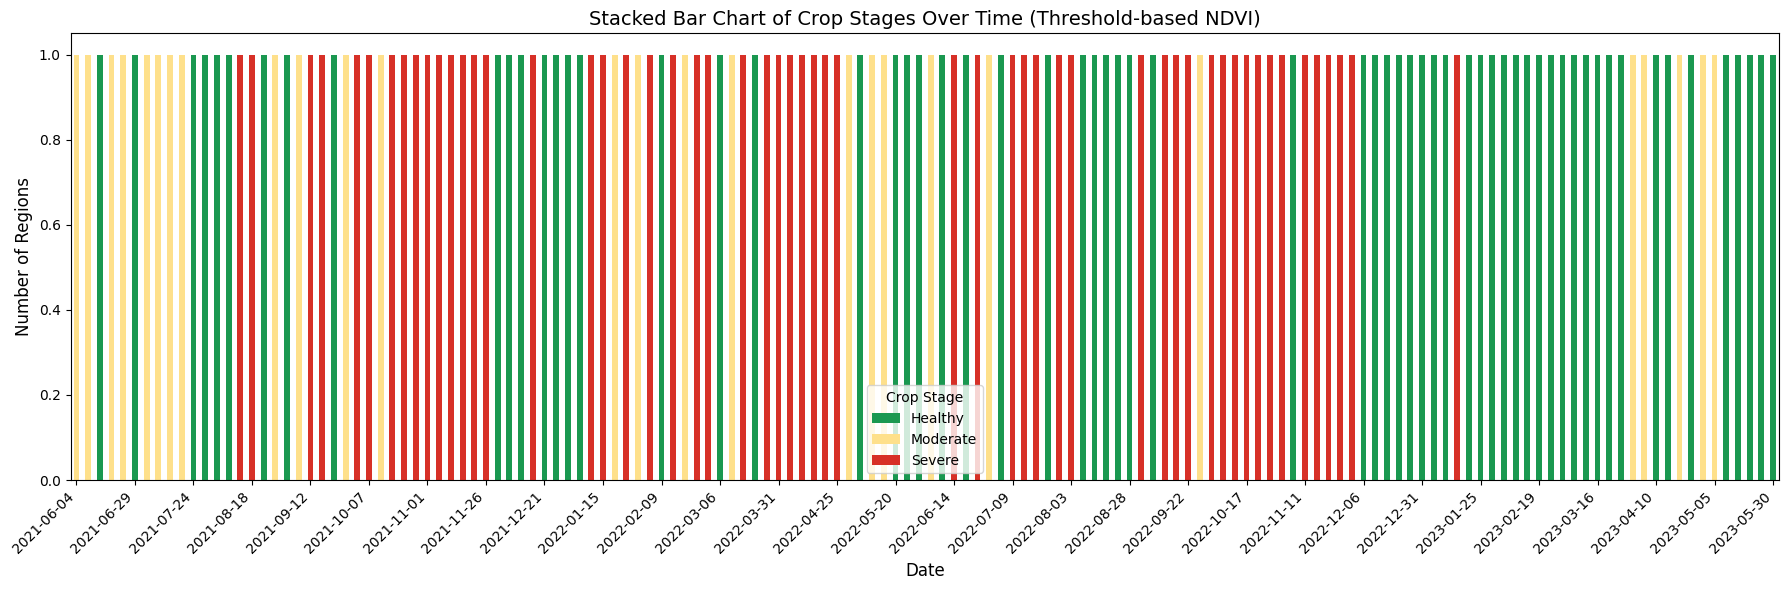

In [ ]:
# STACKED BAR CHART FOR THRESHOLD NDVI

import pandas as pd
import matplotlib.pyplot as plt

# Load your prediction results
df = pd.read_csv("Naive_Bayes_Thar_Model_Aggregated_Daily_VI_STANDARDIZED.csv")

# If labels not already assigned, apply NDMI-based crop stage logic
def label_crop_stage(ndmi):
    if ndmi < -0.2:
        return 'Severe'
    elif ndmi <= 0.1:
        return 'Moderate'
    else:
        return 'Healthy'

df['label'] = df['ndmi'].apply(label_crop_stage)

# Group by date and crop stage
grouped = df.groupby(['date', 'label']).size().unstack(fill_value=0)

# Sort by date
grouped = grouped.sort_index()

# Create the plot
fig, ax = plt.subplots(figsize=(18, 6))

grouped.plot(kind='bar', stacked=True, ax=ax,
             color={'Severe': '#d73027', 'Moderate': '#fee08b', 'Healthy': '#1a9850'})

# Improve date visibility
ax.set_xticks(range(0, len(grouped.index), max(1, len(grouped.index) // 25)))  # limit ticks
ax.set_xticklabels(grouped.index[::max(1, len(grouped.index) // 25)], rotation=45, ha='right')

# Titles and labels
plt.title("Stacked Bar Chart of Crop Stages Over Time (Threshold-based NDVI)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Number of Regions", fontsize=12)
plt.legend(title="Crop Stage")
plt.tight_layout()
plt.show()